# Laboratorio: Modelado de Secuencias y Problema del Gradiente

## Contexto
Imagina que eres analista de sentimiento financiero. Vas a leer noticias largas, pero el sentimiento verdadero esta determinado por la primera palabra:

- `GANANCIA` -> sentimiento positivo (1)
- `PERDIDA` -> sentimiento negativo (0)

## Pregunta central
Si la pista importante aparece al inicio de una secuencia larga, una Vanilla RNN puede recordarla hasta el final?

## Objetivos de aprendizaje
1. Construir una RNN manual en PyTorch.
2. Monitorear como evoluciona la norma del gradiente.
3. Comparar secuencias cortas vs largas.
4. Verificar que `nn.RNN` (vanilla) mantiene el mismo reto.

## Ruta del notebook
1. Datos sinteticos
2. `CustomRNN` (desde cero)
3. Cementerio de gradientes
4. `TorchRNN` con `nn.RNN`
5. Retos para profundizar

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 1) DATOS SINTETICOS
# La etiqueta depende solo del primer paso temporal.
def generate_financial_news(seq_len, num_samples):
    X = torch.randn(num_samples, seq_len, 1)
    y = (X[:, 0, :] > 0).float()
    return X, y

SEQ_LENGTH = 50
X_train, y_train = generate_financial_news(SEQ_LENGTH, 1000)

print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('Proporcion de clase positiva:', y_train.mean().item())

# Verificacion rapida: la etiqueta sigue el signo del primer valor.
sample_idx = 0
print('Primer valor de ejemplo 0:', X_train[sample_idx, 0, 0].item())
print('Etiqueta de ejemplo 0:', y_train[sample_idx, 0].item())

X_train shape: torch.Size([1000, 50, 1])
y_train shape: torch.Size([1000, 1])
Proporcion de clase positiva: 0.4959999918937683
Primer valor de ejemplo 0: 1.9269150495529175
Etiqueta de ejemplo 0: 1.0


### Mini analisis guiado
Antes de entrenar, responde:

1. Si la etiqueta depende del primer token, por que una red que solo mira el ultimo estado oculto podria fallar con secuencias largas?
2. Que esperas que pase con el gradiente cuando el largo de secuencia aumenta?

In [2]:
# 2) RNN DESDE CERO

class CustomRNN(nn.Module):
    def __init__(self, input_sz, hidden_sz, output_sz):
        super().__init__()
        self.hidden_sz = hidden_sz
        self.rnn_cell = nn.Linear(input_sz + hidden_sz, hidden_sz)
        self.fc = nn.Linear(hidden_sz, output_sz)
        self.tanh = nn.Tanh()

    def forward(self, x):
        batch_sz, seq_sz, _ = x.size()
        hidden = torch.zeros(batch_sz, self.hidden_sz, device=x.device)

        for t in range(seq_sz):
            combined = torch.cat((x[:, t, :], hidden), dim=1)
            hidden = self.tanh(self.rnn_cell(combined))

        return torch.sigmoid(self.fc(hidden))


def accuracy_from_probs(probs, y_true):
    preds = (probs >= 0.5).float()
    return (preds == y_true).float().mean().item()

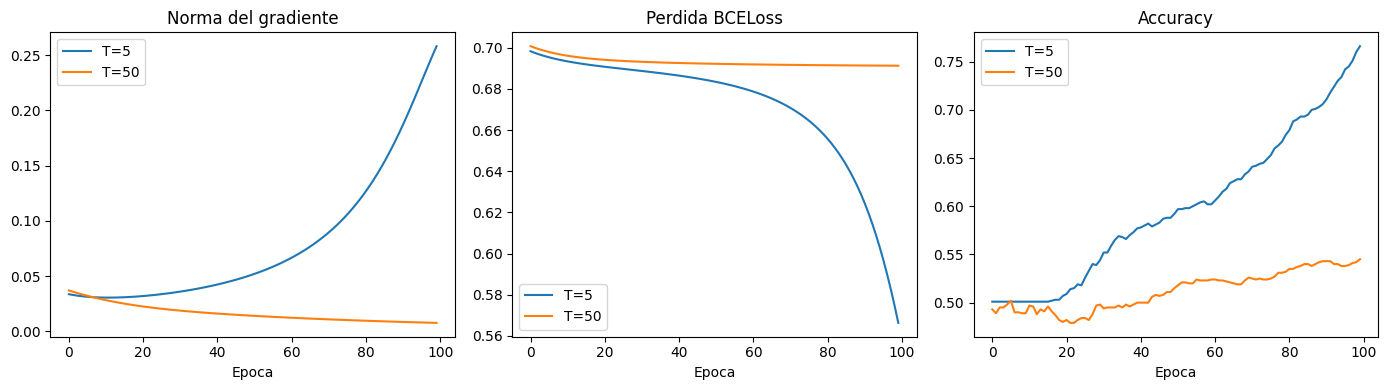

Accuracy final T=5 : 0.766
Accuracy final T=50: 0.545


In [3]:
# 3) CEMENTERIO DE LOS GRADIENTES

def train_and_monitor(model, seq_len, epochs=100, lr=0.1):
    X, y = generate_financial_news(seq_len, 1000)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    criterion = nn.BCELoss()

    grad_history = []
    loss_history = []
    acc_history = []

    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()

        out = model(X)
        loss = criterion(out, y)
        loss.backward()

        grad_norm = model.rnn_cell.weight.grad.norm().item()
        grad_history.append(grad_norm)
        loss_history.append(loss.item())
        acc_history.append(accuracy_from_probs(out.detach(), y))

        optimizer.step()

    return grad_history, loss_history, acc_history

model_short = CustomRNN(1, 16, 1)
model_long = CustomRNN(1, 16, 1)

grads_short, losses_short, acc_short = train_and_monitor(model_short, seq_len=5)
grads_long, losses_long, acc_long = train_and_monitor(model_long, seq_len=50)

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.plot(grads_short, label='T=5')
plt.plot(grads_long, label='T=50')
plt.title('Norma del gradiente')
plt.xlabel('Epoca')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(losses_short, label='T=5')
plt.plot(losses_long, label='T=50')
plt.title('Perdida BCELoss')
plt.xlabel('Epoca')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(acc_short, label='T=5')
plt.plot(acc_long, label='T=50')
plt.title('Accuracy')
plt.xlabel('Epoca')
plt.legend()

plt.tight_layout()
plt.show()

print('Accuracy final T=5 :', round(acc_short[-1], 4))
print('Accuracy final T=50:', round(acc_long[-1], 4))

### Interpreta esta grafica
Si observas que la curva de gradiente para `T=50` cae mas rapido que para `T=5`, eso indica desvanecimiento. Esto suele degradar la capacidad de recordar informacion temprana.

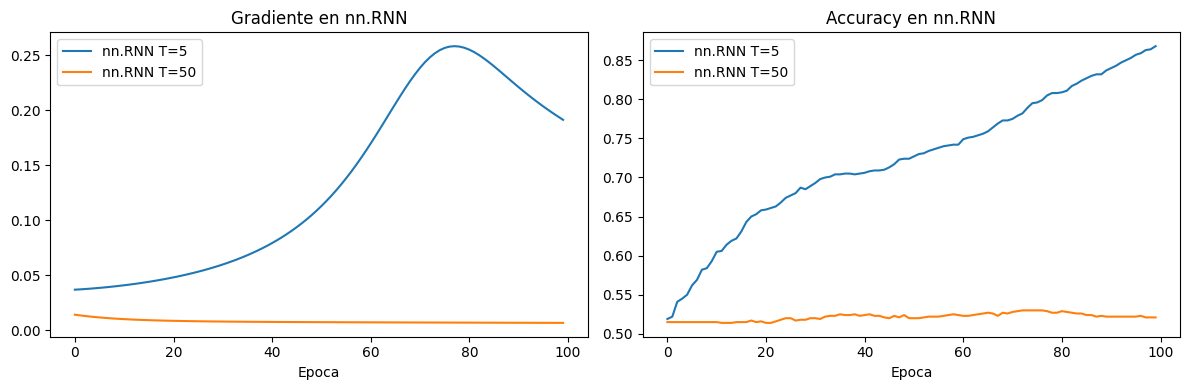

Accuracy final nn.RNN T=5 : 0.868
Accuracy final nn.RNN T=50: 0.521


In [4]:
# 4) COMPARACION CON nn.RNN (Vanilla)

class TorchRNN(nn.Module):
    def __init__(self, input_sz, hidden_sz, output_sz):
        super().__init__()
        self.rnn = nn.RNN(input_sz, hidden_sz, batch_first=True)
        self.fc = nn.Linear(hidden_sz, output_sz)

    def forward(self, x):
        _, h = self.rnn(x)
        return torch.sigmoid(self.fc(h.squeeze(0)))


def train_torch_rnn(seq_len, epochs=100, lr=0.1):
    X, y = generate_financial_news(seq_len, 1000)
    model = TorchRNN(1, 16, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    criterion = nn.BCELoss()

    grad_history, acc_history = [], []

    for _ in range(epochs):
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()

        grad_norm = model.rnn.weight_hh_l0.grad.norm().item()
        grad_history.append(grad_norm)
        acc_history.append(accuracy_from_probs(out.detach(), y))

        optimizer.step()

    return model, grad_history, acc_history

_, grads_torch_short, acc_torch_short = train_torch_rnn(seq_len=5)
_, grads_torch_long, acc_torch_long = train_torch_rnn(seq_len=50)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(grads_torch_short, label='nn.RNN T=5')
plt.plot(grads_torch_long, label='nn.RNN T=50')
plt.title('Gradiente en nn.RNN')
plt.xlabel('Epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(acc_torch_short, label='nn.RNN T=5')
plt.plot(acc_torch_long, label='nn.RNN T=50')
plt.title('Accuracy en nn.RNN')
plt.xlabel('Epoca')
plt.legend()

plt.tight_layout()
plt.show()

print('Accuracy final nn.RNN T=5 :', round(acc_torch_short[-1], 4))
print('Accuracy final nn.RNN T=50:', round(acc_torch_long[-1], 4))

## 5) Actividades para el estudiante

### Actividad A. Sensibilidad de la activacion
1. En `CustomRNN`, reemplaza `nn.Tanh()` por `nn.ReLU()`.
2. Repite el experimento para `T=5` y `T=50`.
3. Responde: el gradiente se desvanece menos, se mantiene o explota?

### Actividad B. Arquitectura Many-to-Many
1. Modifica `forward` para retornar una prediccion por cada tiempo `t`.
2. Ajusta el target para que tenga forma `(batch, seq, 1)`.
3. Compara desempeno con la version many-to-one.

### Actividad C. Reflexion teorica (Goodfellow)
Busca por que, al retropropagar en el tiempo, aparecen productos repetidos de Jacobianos relacionados con potencias de la matriz recurrente:

$$
\frac{\partial h_t}{\partial h_0} \approx \prod_{k=1}^{t} W_k
$$

Cuando el radio espectral es menor que 1, los terminos tienden a encogerse (desvanecimiento). Si es mayor que 1, pueden crecer (explosion).

### Bonus
Compara con una `nn.LSTM` o `nn.GRU` y discute por que suelen manejar mejor dependencias largas.